In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA


#Task 1 - Первичный осмотр и очистка данных

In [5]:
df = pd.read_csv('../data/dirty_cafe_sales.csv')

In [6]:
# Просмотрим информацию о данных
print(f'Число строк датасета = {df.shape[0]}, количество столбцов = {df.shape[1]}')
print('----------------------------------------------------')
print('Столбцы и типы данных их значений:')
print(df.dtypes)
print('----------------------------------------------------')
print(f'Количество пропущенных значений = {df.isna().sum().sum()}')
print('----------------------------------------------------')
print('Пропущенные значения по столбцам:')
print(df.isna().sum())
print('----------------------------------------------------')
print('Вид датасета (первые 5 элементов):')
print(df.head(5))
print('----------------------------------------------------')
print('Вид датасета (последние 5 элементов):')
print(df.tail(5))
print('----------------------------------------------------')
print('Базовая статистика:')
print(df.describe())
print('----------------------------------------------------')

# Создаём тестовый, неочищенный датасет
df_not_clean = df.copy()

Число строк датасета = 10000, количество столбцов = 8
----------------------------------------------------
Столбцы и типы данных их значений:
Transaction ID      str
Item                str
Quantity            str
Price Per Unit      str
Total Spent         str
Payment Method      str
Location            str
Transaction Date    str
dtype: object
----------------------------------------------------
Количество пропущенных значений = 6826
----------------------------------------------------
Пропущенные значения по столбцам:
Transaction ID         0
Item                 333
Quantity             138
Price Per Unit       179
Total Spent          173
Payment Method      2579
Location            3265
Transaction Date     159
dtype: int64
----------------------------------------------------
Вид датасета (первые 5 элементов):
  Transaction ID    Item Quantity Price Per Unit Total Spent  Payment Method  \
0    TXN_1961373  Coffee        2            2.0         4.0     Credit Card   
1    TXN_497

In [7]:
# Удалим дубликаты (если они есть)

# Создаём тестовый, неочищенный датасет
df_not_clean = df.copy()

before_clean = df_not_clean.shape[0]  # Помещаем в переменную колличество строк из тестового (неочищенного) блока данных, созданного в верхнем блоке.
df = df.drop_duplicates().reset_index(drop=True)  # Чистим наш основной data-set, если он содержит дубликаты - они будут удалены и индексы будут рассчитаны заново
after_clean = df.shape[0] # Помещаем в переменную колличество строк из основного блока данных, после удаления дубликатов (если они были найдены).
if before_clean == after_clean:
  print('Data-set не содержит дубликатов')
else:
  print(f'Размер датасета, до удаления строк-дубликатов: {before_clean}')
  print('----------------------------------------------------')
  print(f'Размер датасета, после удаления строк-дубликатов: {after_clean}')
  print('----------------------------------------------------')
  print(f'Удалено строк: {before_clean - after_clean}')
  print(df.head())

Data-set не содержит дубликатов


In [8]:
# Переведём значения колонки с датами в тип datetime:
df['Transaction Date'] = pd.to_datetime(df['Transaction Date'], errors='coerce')

In [9]:
# Для дальнейшего анализа нам необходимо будет, чтобы значение колонки
# Item - было корректно, проверим, какие данные содержит данная колонка
print(f'Типы данных в данном столбце: {df['Item'].unique()}')


Типы данных в данном столбце: <StringArray>
[  'Coffee',     'Cake',   'Cookie',    'Salad', 'Smoothie',  'UNKNOWN',
 'Sandwich',        nan,    'ERROR',    'Juice',      'Tea']
Length: 11, dtype: str


In [10]:
# Создадим функцию, которая будет удалять все строки из таблицы, если хоть одно значение в интересующей нас колонке будет NaN,
# а также пропишим удаление конкретных 'ошибочных' значений, которые были найдены в верхней строчке кода ('UNKNOWN', 'ERROR').
# На вход функция будет принимать имя датасета и название колонки
def drop_invalid_categories(df, column_name):
  df = df.dropna(subset=[column_name]).reset_index(drop=True)
  df = df.loc[df[column_name] != 'UNKNOWN'].loc[df[column_name] != 'ERROR']
  return df

df = drop_invalid_categories(df, 'Item')
print(f'Ошибочных значений по столбцу Item: было={df_not_clean['Item'].isna().sum()
                                                    + (df_not_clean['Item'] == 'UNKNOWN').sum()
                                                    + (df_not_clean['Item'] == 'ERROR').sum()}, стало={df['Item'].isna().sum()}')
print(f'Типы данных в данном столбце: {df['Item'].unique()}')

Ошибочных значений по столбцу Item: было=969, стало=0
Типы данных в данном столбце: <StringArray>
['Coffee', 'Cake', 'Cookie', 'Salad', 'Smoothie', 'Sandwich', 'Juice', 'Tea']
Length: 8, dtype: str


In [11]:
# Значения столбцов до обработки
print(df['Quantity'].unique())
print(df['Price Per Unit'].unique())
print(df['Total Spent'].unique())

<StringArray>
['2', '4', '5', '3', '1', 'ERROR', 'UNKNOWN', nan]
Length: 8, dtype: str
<StringArray>
['2.0', '3.0', '1.0', '5.0', '4.0', '1.5', nan, 'ERROR', 'UNKNOWN']
Length: 9, dtype: str
<StringArray>
[    '4.0',    '12.0',   'ERROR',    '10.0',    '20.0',    '16.0',    '25.0',
     '8.0',     '5.0',    '15.0',     '6.0',       nan, 'UNKNOWN',     '2.0',
     '9.0',     '3.0',     '1.0',     '7.5',     '4.5',     '1.5']
Length: 20, dtype: str


In [12]:
# Переведём все значения данных колонок в числа
# (ошибочные значения заменим на NaN):
def num_transformation(df, *column_names):
  for col in column_names:
    df[col] = pd.to_numeric(df[col], errors='coerce')
  return df

df = num_transformation(df, 'Quantity', 'Price Per Unit', 'Total Spent')

In [13]:
# Вывод после обработки:
print(df['Quantity'].unique())
print(df['Price Per Unit'].unique())
print(df['Total Spent'].unique())

[ 2.  4.  5.  3.  1. nan]
[2.  3.  1.  5.  4.  1.5 nan]
[ 4.  12.   nan 10.  20.  16.  25.   8.   5.  15.   6.   2.   9.   3.
  1.   7.5  4.5  1.5]


In [14]:
# Резульаты очистки датасета:

In [15]:
def fix_transaction_data(df, items, quantity, price_per_unit, total_spent, payment_method):
    """
    Обработка пропусков с явной обработкой ВСЕХ комбинаций
    """
    df = df.copy()  # Не изменяем оригинал

    # === ШАГ 1: Простые случаи (один пропуск) ===

    # 1.1 Только Total Spent NaN (известны Quantity и Price)
    mask = (df[quantity].notna() & df[price_per_unit].notna() & df[total_spent].isna())
    if mask.any():
        df.loc[mask, total_spent] = df.loc[mask, quantity] * df.loc[mask, price_per_unit]
        print(f"Заполнено Total Spent: {mask.sum()} строк")

    # 1.2 Только Price Per Unit NaN (известны Quantity и Total)
    mask = (df[quantity].notna() & df[price_per_unit].isna() & df[total_spent].notna())
    if mask.any():
        safe = df.loc[mask, quantity] != 0
        if safe.any():
            df.loc[mask & safe, price_per_unit] = df.loc[mask & safe, total_spent] / df.loc[mask & safe, quantity]
        print(f"Заполнено Price Per Unit: {mask.sum()} строк")

    # 1.3 Только Quantity NaN (известны Price и Total)
    mask = (df[quantity].isna() & df[price_per_unit].notna() & df[total_spent].notna())
    if mask.any():
        safe = df.loc[mask, price_per_unit] != 0
        if safe.any():
            df.loc[mask & safe, quantity] = df.loc[mask & safe, total_spent] / df.loc[mask & safe, price_per_unit]
        print(f"Заполнено Quantity: {mask.sum()} строк")

    # === ШАГ 2: Сложные случаи (два пропуска) ===

    # 2.1 Price и Total NaN (известен только Quantity)
    mask = (df[quantity].notna() & df[price_per_unit].isna() & df[total_spent].isna())
    if mask.any():
        group_mean = df.groupby(items)[price_per_unit].transform('mean')
        df.loc[mask, price_per_unit] = group_mean[mask]
        df.loc[mask, total_spent] = df.loc[mask, quantity] * df.loc[mask, price_per_unit]
        df.loc[mask, payment_method] = np.nan
        print(f"Заполнено Price+Total: {mask.sum()} строк")

    # 2.2 Quantity и Total NaN (известен только Price)
    mask = (df[quantity].isna() & df[price_per_unit].notna() & df[total_spent].isna())
    if mask.any():
        df.loc[mask, quantity] = 1
        df.loc[mask, total_spent] = df.loc[mask, price_per_unit]
        df.loc[mask, payment_method] = np.nan
        print(f"Заполнено Quantity+Total: {mask.sum()} строк")

    # 2.3 Quantity и Price NaN (известен только Total)
    mask = (df[quantity].isna() & df[price_per_unit].isna() & df[total_spent].notna())
    if mask.any():
        group_mean = df.groupby(items)[price_per_unit].transform('mean')
        df.loc[mask, price_per_unit] = group_mean[mask]
        safe = df.loc[mask, price_per_unit] != 0
        if safe.any():
            df.loc[mask & safe, quantity] = df.loc[mask & safe, total_spent] / df.loc[mask & safe, price_per_unit]
        df.loc[mask, payment_method] = np.nan
        print(f"Заполнено Quantity+Price: {mask.sum()} строк")

    # === ШАГ 3: Все три пропуска ===

    mask = (df[quantity].isna() & df[price_per_unit].isna() & df[total_spent].isna())
    if mask.any():
        group_mean = df.groupby(items)[price_per_unit].transform('mean')
        df.loc[mask, quantity] = 1
        df.loc[mask, price_per_unit] = group_mean[mask]
        df.loc[mask, total_spent] = df.loc[mask, price_per_unit]
        df.loc[mask, payment_method] = np.nan
        print(f"Заполнено всё: {mask.sum()} строк")

    # === ШАГ 4: Финальная очистка ===

    # Удаляем строки где все еще есть NaN (если они остались)
    remaining_na = df[[quantity, price_per_unit, total_spent]].isna().any(axis=1).sum()
    if remaining_na > 0:
        print(f"\nУдалено {remaining_na} строк с неудаваемыми пропусками")
        df = df.dropna(subset=[quantity, price_per_unit, total_spent])

    return df.reset_index(drop=True)

In [16]:
df = fix_transaction_data(
    df,
    'Item',
    'Quantity',
    'Price Per Unit',
    'Total Spent',
    'Payment Method'
)

# Проверка
print("\n=== ИТОГОВАЯ ПРОВЕРКА ===")
print(df[['Quantity', 'Price Per Unit', 'Total Spent', 'Payment Method']].isna().sum())

Заполнено Total Spent: 415 строк
Заполнено Price Per Unit: 447 строк
Заполнено Quantity: 385 строк
Заполнено Price+Total: 17 строк
Заполнено Quantity+Total: 20 строк
Заполнено Quantity+Price: 15 строк

=== ИТОГОВАЯ ПРОВЕРКА ===
Quantity             0
Price Per Unit       0
Total Spent          0
Payment Method    2369
dtype: int64


In [17]:
def output_result(df, column_name, clean_df=True):
  if clean_df == True:
    print(f'Значение столбца {column_name} после обработки: {df[column_name].unique()}')
    print(f'Тип данных столбца {column_name} после обработки: {df[column_name].dtype}')
  else:
    print(f'Значение столбца {column_name} до обработки: {df[column_name].unique()}')
    print(f'Тип данных столбца {column_name} до обработки: {df[column_name].dtype}')

output_result(df_not_clean, 'Quantity', False)
output_result(df, 'Quantity', True)
print('----------------------------------------------------')
output_result(df_not_clean, 'Price Per Unit', False)
output_result(df, 'Price Per Unit', True)
print('----------------------------------------------------')
output_result(df_not_clean, 'Total Spent', False)
output_result(df, 'Total Spent', True)
print('----------------------------------------------------')
output_result(df_not_clean, 'Item', False)
output_result(df, 'Item', True)

Значение столбца Quantity до обработки: <StringArray>
['2', '4', '5', '3', '1', 'ERROR', 'UNKNOWN', nan]
Length: 8, dtype: str
Тип данных столбца Quantity до обработки: str
Значение столбца Quantity после обработки: [2. 4. 5. 3. 1.]
Тип данных столбца Quantity после обработки: float64
----------------------------------------------------
Значение столбца Price Per Unit до обработки: <StringArray>
['2.0', '3.0', '1.0', '5.0', '4.0', '1.5', nan, 'ERROR', 'UNKNOWN']
Length: 9, dtype: str
Тип данных столбца Price Per Unit до обработки: str
Значение столбца Price Per Unit после обработки: [2.  3.  1.  5.  4.  1.5]
Тип данных столбца Price Per Unit после обработки: float64
----------------------------------------------------
Значение столбца Total Spent до обработки: <StringArray>
[    '4.0',    '12.0',   'ERROR',    '10.0',    '20.0',     '9.0',    '16.0',
    '15.0',    '25.0',     '8.0',     '5.0',     '3.0',     '6.0',       nan,
 'UNKNOWN',     '2.0',     '1.0',     '7.5',     '4.5',    

In [18]:
print(f'размер данных до очистки: строк = {df_not_clean.shape[0]}, столбцов = {df_not_clean.shape[1]}')
print(f'размер данных после очистки: строк = {df.shape[0]}, столбцов = {df.shape[1]}')

размер данных до очистки: строк = 10000, столбцов = 8
размер данных после очистки: строк = 9031, столбцов = 8


In [19]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9031 entries, 0 to 9030
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction ID    9031 non-null   str           
 1   Item              9031 non-null   str           
 2   Quantity          9031 non-null   float64       
 3   Price Per Unit    9031 non-null   float64       
 4   Total Spent       9031 non-null   float64       
 5   Payment Method    6662 non-null   str           
 6   Location          6086 non-null   str           
 7   Transaction Date  8613 non-null   datetime64[us]
dtypes: datetime64[us](1), float64(3), str(4)
memory usage: 564.6 KB


# Task 2 - Исследовательский анализ данных (EDA). (Поиск закономерностей и зависимостей)

In [20]:
# Выведем график среднего чека в зависимости от месяца

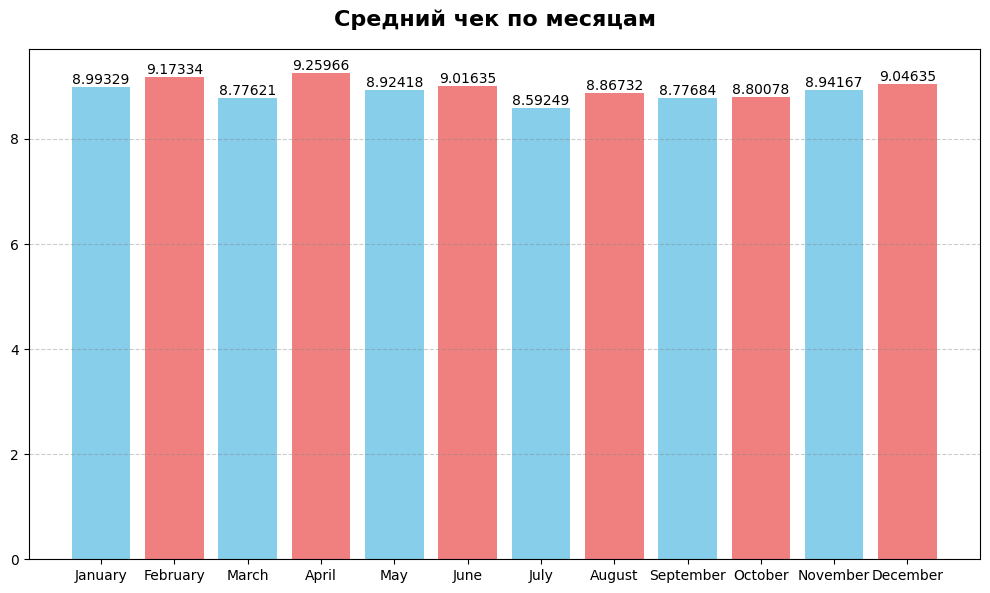

In [21]:
months = {
    1:"January", 2:"February", 3:"March", 4:"April",
    5:"May", 6:"June", 7:"July", 8:"August",
    9:"September", 10:"October", 11:"November", 12:"December"
}
df_months_mean = df.copy()
df_months_mean['Month'] = df_months_mean['Transaction Date'].dt.month
df_months_mean['Month Name'] = df_months_mean['Month'].map(months)

# Перестроим последовательность месяцев, чтобы при отображении на графике они указывались не по алфавиту,
# а последовательно, как в календаре
# Правильный порядок месяцев
month_order = ["January", "February", "March", "April", "May", "June",
               "July", "August", "September", "October", "November", "December"]

average_check = df_months_mean.groupby('Month Name')['Total Spent'].mean().reindex(month_order)


# Выведем данные на графике
fig, ax = plt.subplots(figsize=(10, 6))
fig.suptitle('Средний чек по месяцам', fontsize=16, fontweight='bold')
bars = ax.bar(average_check.index, average_check.values, color=['skyblue', 'lightcoral'])
ax.bar_label(bars)
ax.grid(True, alpha=0.4, axis='y', linestyle='--', color='gray')

plt.tight_layout()
plt.show()


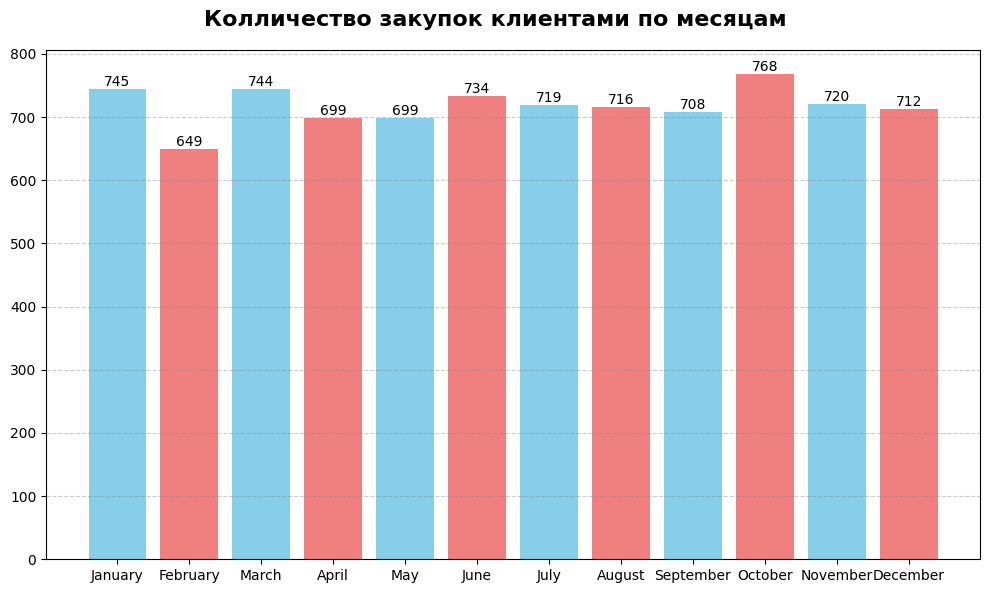

In [22]:
# Выведем график колличества закупок по месяцам
number_of_purchases = df_months_mean.groupby('Month Name')['Total Spent'].count().reindex(month_order)

fig, ax = plt.subplots(figsize=(10, 6))
fig.suptitle('Колличество закупок клиентами по месяцам', fontsize=16, fontweight='bold')
bars = ax.bar(number_of_purchases.index, number_of_purchases.values, color=['skyblue', 'lightcoral'])
ax.bar_label(bars)
ax.grid(True, alpha=0.4, axis='y', linestyle='--', color='gray')

plt.tight_layout()
plt.show()


In [23]:
# Расчет выручки (количество × средний чек) показывает:
revenue = (number_of_purchases * average_check).sort_values()
print(revenue)

Month Name
February     5953.5
July         6178.0
September    6214.0
May          6238.0
August       6349.0
November     6438.0
December     6441.0
April        6472.5
March        6529.5
June         6618.0
January      6700.0
October      6759.0
Name: Total Spent, dtype: float64


In [24]:
# Данные показывают общую картину по продажам. Месяцы-лидеры по среднему чеку:
# апрель (9.26), февраль (9.17), декабрь (9.05).
# Месяцы с наименьшим средним чеком: июль (8.59), март (8.78).

# Однако наблюдается обратная корреляция между количеством закупок и средним чеком:
# - Октябрь имеет максимальное количество закупок (768), но средний чек ниже (8.80)
# - Февраль имеет минимальное количество закупок (649), но высокий средний чек (9.17)

# Расчет выручки показывает:
# - Лидеры по выручке: октябрь (6759), январь (6,700), июнь (6,618)
# - Аутсайдеры: февраль (5953), июль (6178)

# Вывод: Существует обратная зависимость между частотой покупок и средним чеком.
# В месяцы с высокой активностью (октябрь, январь) клиенты совершают больше покупок,
# но на меньшие суммы — вероятно, это массовый спрос на товары повседневного спроса.
# В месяцы с низкой активностью (февраль, апрель) клиенты покупают реже, но тратят
# больше за транзакцию — возможно, это сезонный спрос на более дорогие товары или
# накопительный эффект. Для максимизации выручки необходимо балансировать оба показателя.

In [25]:
# Проверим распределение среднего чека на наличие аномалий

In [26]:
# Выведем медиану
Total_spent_median = df['Total Spent'].median()
Total_spent_mean = df['Total Spent'].mean()
print(f'Значение медианы: {Total_spent_median}')
print(f'Значение средний: {Total_spent_mean:.1f}')
print(f'Разность значений: {abs(Total_spent_mean - Total_spent_median):.1f}')

Значение медианы: 8.0
Значение средний: 8.9
Разность значений: 0.9


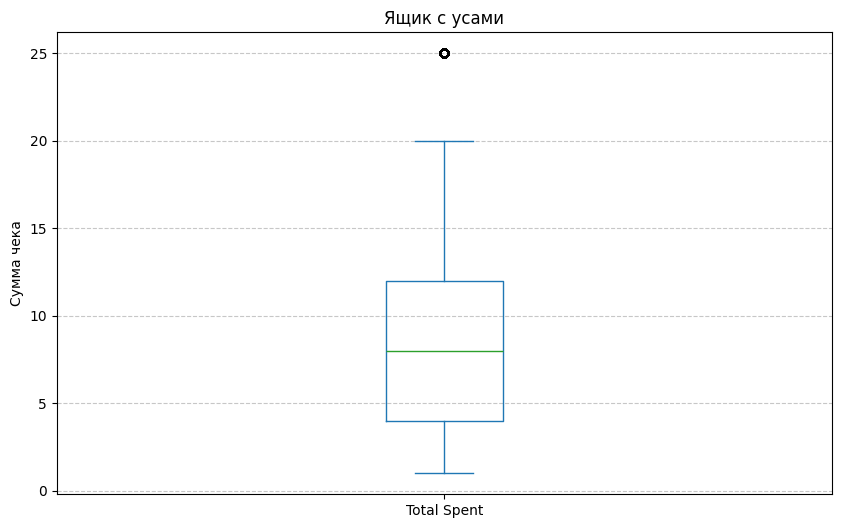

In [27]:
# Ящик с усами
df['Total Spent'].plot.box(figsize=(10, 6), title='Ящик с усами')
plt.ylabel('Сумма чека')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [28]:
# Мы выявили явное аномальное значение (их может быть больше чем одно),
# Оно составляет 25. Просмотри количество данных с таким значением

In [29]:
print(f'Колличество записей с общей суммой покупки = 25: {len(df[df['Total Spent'] == 25])}')

Колличество записей с общей суммой покупки = 25: 248


In [30]:
# Высчитаем процентное соотношение данных записей от всех данных
print(f'Процент записей чей чек = 25: {((len(df[df['Total Spent'] == 25]) * 100) / len(df)):.1f}%')

Процент записей чей чек = 25: 2.7%


In [31]:
# Вывод, данные транзакции не единичны, следовательно столбцы, чья общая
# сумма составляет 25 - не являются аномалиями.
# Для последующего обучения модели данные столбцы будут оставлены.

In [32]:
# Проверим 'на глаз' разницу в чеках в зависимости от способа оплаты

In [33]:
# Методы оплаты из таблицы
print(df['Payment Method'].unique())

<StringArray>
['Credit Card', 'Cash', 'UNKNOWN', 'Digital Wallet', nan, 'ERROR']
Length: 6, dtype: str


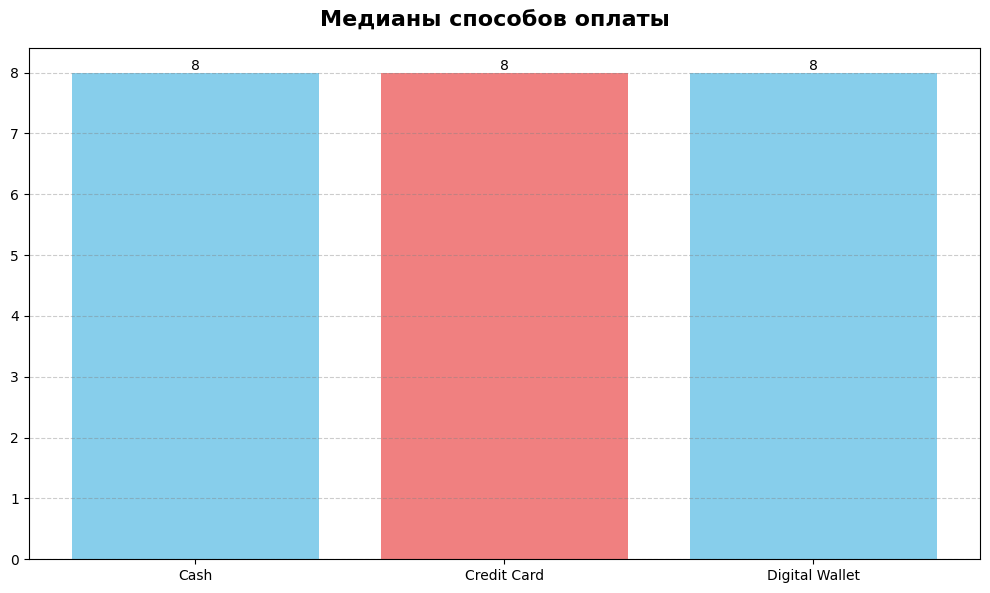

In [34]:
# Нас будут интересовать методы оплаты: 'Cash', 'Digital Wallet', 'Credit Card'
# Просмотри разницу в медианах:

# Считаем данные
valid_methods = ['Cash', 'Digital Wallet', 'Credit Card'] # Список допустимых способов оплаты
df_filtered = df[df['Payment Method'].isin(valid_methods)] # Фильтруем данные
median_by_payment = df_filtered.groupby('Payment Method')['Total Spent'].median()

fig, ax = plt.subplots(figsize=(10, 6))
fig.suptitle('Медианы способов оплаты', fontsize=16, fontweight='bold')
bars = ax.bar(median_by_payment.index, median_by_payment.values, color=['skyblue', 'lightcoral'])
ax.bar_label(bars)
ax.grid(True, alpha=0.4, axis='y', linestyle='--', color='gray')

plt.tight_layout()
plt.show()

In [35]:
# Как мы видим при беглом осмотре данных - разница в чеках, в зависимости от разных способов оплаты,
# не изменяется.
# Для большей уверенности проведём статистический тест.
# Выведем гипотезу в следующем блоке.

# Task 3 - Статистический анализ и проверка гипотезы

In [36]:
# Гипотеза 1: Наличными платят меньше, чем электронными способами оплаты
# Гипотеза H0 - Значения среднего чека при оплате наличными и безналичным способом статистически неразличимы
#               (способ оплаты не влияет на величину чека)

# Гипотеза H1 - Средний чек при безналичной оплате выше, чем при оплате наличными
#               (способ оплаты влияет на величину чека)

In [37]:
# Просмотрим колличество категорий товаров, которые у нас есть в таблице
print(df['Item'].unique())
print(f'Колличество позиций: {df['Item'].nunique()}')


<StringArray>
['Coffee', 'Cake', 'Cookie', 'Salad', 'Smoothie', 'Sandwich', 'Juice', 'Tea']
Length: 8, dtype: str
Колличество позиций: 8


In [38]:
# Т.к. 'Digital Wallet' и 'Credit Card' - это способы безналичной оплаты, а наша гипотеза звучала как:
# 'Наличными платят меньше, чем электронными способами оплаты' - мы будем сравнивать данные с покупками,
# оплаченными наличными сначало с данными о покупках, купленных по карточке; после, мы также сравним
# данные с покупками, оплаченными наличными, но уже с данными о покупках, оплаченных по кредитной карточке.

# Только в случае, если ОБА ЭТИХ ТЕСТА покажут значимые статистические показатели - мы отвергнем нулевую гипотезу
# в пользу альтернативной.

In [39]:
# Блок со способом оплаты:
payment_method_list = ['Cash', 'Digital Wallet', 'Credit Card']

In [40]:
# Перед выбором статистического метода для проверки нашей гипотезы - проверим сами данные

In [41]:
# Создадим функцию для проверки нормальности распределения с помощью теста Шапиро-Уилка
# и проверки равенства дисперсий с помощью теста Левена
def test_Shapiro_Levena(df, payment_method, payment_method_list, total_spent):
  # Проверим нормальность распределения с помощью теста Шапиро-Уилка:
  for i in payment_method_list:
    data = df[df[payment_method] == i]
    data = data[total_spent]
    stat, p = stats.shapiro(data)
    print(f'Тест Шапиро ({i}) : W={stat:.3f}, p-value={p:.3f} -> {"Нормальное" if p > 0.05 else "НЕ нормальное"} распределение')

  # Проверим равенство дисперсий с помощью теста Левена:
  # Сравниваем 'Cash' с 'Digital Wallet' и
  # 'Cash' с 'Credit Card'

  cash_use_mask = df[df[payment_method] == payment_method_list[0]]
  cash = cash_use_mask[total_spent]
  digital_use_mask = df[df[payment_method] == payment_method_list[1]]
  digital = digital_use_mask[total_spent]
  credit_use_mask = df[df[payment_method] == payment_method_list[2]]
  credit = credit_use_mask[total_spent]

  # Проверка данных тестом Левена:
  stat, p_levene = stats.levene(cash, digital)
  print(f'Тест Левене (Cash vs Digital Wallet): W={stat:.3f}, p-value={p_levene:.3f} -> {"Дисперсии равны" if p_levene > 0.05 else "Дисперсии разные"}')

  stat, p_levene = stats.levene(cash, credit)
  print(f'Тест Левене (Cash vs Credit Card): W={stat:.3f}, p-value={p_levene:.3f} -> {"Дисперсии равны" if p_levene > 0.05 else "Дисперсии разные"}')
  print('----------------------------------------------------')


k = test_Shapiro_Levena(df, 'Payment Method', payment_method_list, 'Total Spent')

Тест Шапиро (Cash) : W=0.912, p-value=0.000 -> НЕ нормальное распределение
Тест Шапиро (Digital Wallet) : W=0.912, p-value=0.000 -> НЕ нормальное распределение
Тест Шапиро (Credit Card) : W=0.920, p-value=0.000 -> НЕ нормальное распределение
Тест Левене (Cash vs Digital Wallet): W=0.169, p-value=0.681 -> Дисперсии равны
Тест Левене (Cash vs Credit Card): W=0.453, p-value=0.501 -> Дисперсии равны
----------------------------------------------------


In [42]:
# Учитывая тот факт, что выборка по данным у нас большая (n > 30 для каждой группы) и дисперсии равны -
# мы можем использовать t-тест, для проверки гипотезы, который устойчив к не нормальному распределению данных,
# при большой выборке

# Используем доверительный интервал = 95%

In [43]:
payment_cash = ['Cash']
payment_digital = ['Digital Wallet', 'Credit Card']

def t_test(df, payment_method, payment_cash, payment_digital, total_spent):
  # Создаём маски:
  cash_mask = df[payment_method].isin(payment_cash)
  digital_mask = df[payment_method] == payment_digital[0]
  credit_mask = df[payment_method] == payment_digital[1]
  # Фильтруем данные по маскам:
  cash_group = df[cash_mask]
  digital_group = df[digital_mask]
  credit_group = df[credit_mask]
  # Собираем данные в списки
  group_names = [payment_cash, payment_digital[0], payment_digital[1]]  # !st need to test
  groups_data = [
    cash_group[total_spent],
    digital_group[total_spent],
    credit_group[total_spent]
  ]
  # Cash - 1-й в списке (с ним и будет сравнение)
  cash_data = groups_data[0]

  print("\n--- Доверительные интервалы разницы средних (95%) ---")
  for idx in range(1, len(groups_data)):
    other_data = groups_data[idx]
    other_name = group_names[idx]

    res = stats.ttest_ind(other_data, cash_data, equal_var=True)
    ci = res.confidence_interval(confidence_level=0.95)
    #diff_means = other_data.mean() - cash_data.mean()

    print(f"\n{other_name} минус Cash:")
    #print(f"  Разница выборочных средних: {diff_means:.2f}")
    print(f"95% CI: [{ci.low:.2f}, {ci.high:.2f}]")

    if ci.low > 0:
      print(f"Вывод: {other_name} статистически значимо БОЛЬШЕ, чем Cash.")
    elif ci.high < 0:
      print(f"Вывод: {other_name} статистически значимо МЕНЬШЕ, чем Cash.")
    else:
      print(f"Вывод: Статистически значимой разницы с Cash нет (CI содержит 0).")

    print('----------------------------------------------------')


t = t_test(df, 'Payment Method', payment_cash, payment_digital, 'Total Spent')


--- Доверительные интервалы разницы средних (95%) ---

Digital Wallet минус Cash:
95% CI: [-0.56, 0.18]
Вывод: Статистически значимой разницы с Cash нет (CI содержит 0).
----------------------------------------------------

Credit Card минус Cash:
95% CI: [-0.42, 0.32]
Вывод: Статистически значимой разницы с Cash нет (CI содержит 0).
----------------------------------------------------


In [44]:
# Итог: мы не отвергаем нулевую гипотезу H0 — разница средних чеков при оплате наличными и безналичным
# способом статистически незначима (95% CI включает ноль). Таким образом, на основе имеющихся данных
# нельзя сделать вывод о том, что способ оплаты влияет на величину среднего чека

# Task 4 - Создание предсказательной модели

In [45]:
# Создадим модель, которая будет предсказывать способ оплаты клиента:
# наличные (cash) или безнал (digital wallet/credit card).

# Данная модель нацелена на помощь кассирам, таким образом, продавец
# сможет предскзать, в какие дни спрос на оплату деньгами выше - необходимы наличные
# в кассе для размена купюр, а когда об этом можно так сильно не беспокоиться.

# Для решения данной задачи будем использовать Логистическую регрессию

In [46]:
# Для обучения модели нам потребуются следующие данные:
# - Способ оплаты (Payment Method)
# - Итоговый чек - (Total Spent)
# - Категория товара - (Item)
# - Локация магазина - (Location)
# - Выходной или нет? - (нужен столбец, вычленим день недели из столбца Transaction Date)
# - День недели - (нужен столбец, вычленим день недели из столбца Transaction Date)
# - Месяц продажи - (нужен столбец, вычленим день недели из столбца Transaction Date)

In [47]:
# Подготовим данные для модели:
df_model_1 = df[['Payment Method', 'Total Spent', 'Item', 'Location', 'Transaction Date']].copy()

# Оставляем только Cash и Digital Wallet/Credit Card
df_model_1 = df_model_1[df_model_1['Payment Method'].isin(['Cash', 'Credit Card', 'Digital Wallet'])]

# Превращаем текстовое представление данных в числовое
df_model_1['is_cashless'] = df_model_1['Payment Method'].apply(
  lambda x: 1 if x in ['Credit Card', 'Digital Wallet'] else 0)

In [48]:
def output(df, name_col):
  for i in name_col:
    nan_in_col = df[i].isna().sum()
    print(f'Пропусков в {i}: {nan_in_col}')
    unique_values = df[i].unique()
    print(f'Уникальные значения в {i}: {unique_values}')
    print()
  print('-----------------------------------')
  print(f'Общее колличество строк: {len(df)}')

test_not_clean = output(df_model_1, ['Total Spent', 'Location', 'Item', 'Transaction Date'])

Пропусков в Total Spent: 0
Уникальные значения в Total Spent: [ 4.  12.  20.  16.  25.   8.  15.   6.   5.  10.   2.   3.   1.   7.5
  9.   4.5  1.5]

Пропусков в Location: 1967
Уникальные значения в Location: <StringArray>
['Takeaway', 'In-store', nan, 'UNKNOWN', 'ERROR']
Length: 5, dtype: str

Пропусков в Item: 0
Уникальные значения в Item: <StringArray>
['Coffee', 'Cake', 'Cookie', 'Smoothie', 'Sandwich', 'Salad', 'Juice', 'Tea']
Length: 8, dtype: str

Пропусков в Transaction Date: 268
Уникальные значения в Transaction Date: <DatetimeArray>
['2023-09-08 00:00:00', '2023-05-16 00:00:00', '2023-07-19 00:00:00',
 '2023-06-11 00:00:00', '2023-03-31 00:00:00', '2023-10-28 00:00:00',
 '2023-11-07 00:00:00',                 'NaT', '2023-05-03 00:00:00',
 '2023-11-15 00:00:00',
 ...
 '2023-09-03 00:00:00', '2023-03-27 00:00:00', '2023-03-10 00:00:00',
 '2023-02-14 00:00:00', '2023-05-11 00:00:00', '2023-11-11 00:00:00',
 '2023-07-03 00:00:00', '2023-12-30 00:00:00', '2023-08-08 00:00:00',
 

In [49]:
# Мы видем, что в столбцах 'Location' и 'Transaction Date' - есть пропуски,
# а также значения 'UNKNOWN' 'ERROR' в столбце - Location,
# пожертвуем частью данных, чтобы модель обучалась на корректных значениях.

In [50]:
df_model_1 = df_model_1.dropna(subset=['Location', 'Transaction Date'])
df_model_1 = df_model_1[(df_model_1['Location'] != 'UNKNOWN') & (df_model_1['Location'] != 'ERROR')]

# Смотрим на результат:
test_cleat = output(df_model_1, ['Total Spent', 'Location', 'Item', 'Transaction Date'])

Пропусков в Total Spent: 0
Уникальные значения в Total Spent: [ 4.  12.  25.   8.  15.   6.  20.  16.   5.  10.   2.   3.   1.   9.
  7.5  4.5  1.5]

Пропусков в Location: 0
Уникальные значения в Location: <StringArray>
['Takeaway', 'In-store']
Length: 2, dtype: str

Пропусков в Item: 0
Уникальные значения в Item: <StringArray>
['Coffee', 'Cake', 'Cookie', 'Salad', 'Sandwich', 'Juice', 'Smoothie', 'Tea']
Length: 8, dtype: str

Пропусков в Transaction Date: 0
Уникальные значения в Transaction Date: <DatetimeArray>
['2023-09-08 00:00:00', '2023-05-16 00:00:00', '2023-07-19 00:00:00',
 '2023-06-11 00:00:00', '2023-11-07 00:00:00', '2023-05-03 00:00:00',
 '2023-11-15 00:00:00', '2023-02-24 00:00:00', '2023-01-15 00:00:00',
 '2023-04-04 00:00:00',
 ...
 '2023-03-07 00:00:00', '2023-07-31 00:00:00', '2023-05-22 00:00:00',
 '2023-03-12 00:00:00', '2023-06-02 00:00:00', '2023-02-18 00:00:00',
 '2023-05-25 00:00:00', '2023-09-24 00:00:00', '2023-01-24 00:00:00',
 '2023-05-13 00:00:00']
Length: 

In [51]:
# Избавляемся от категориальных значений:
df_model_1['Day_of_Week'] = df_model_1['Transaction Date'].dt.day_name()
df_model_1['Month'] = df_model_1['Transaction Date'].dt.month
df_model_1['Is_Weekend'] = df_model_1['Day_of_Week'].isin(['Saturday', 'Sunday']).astype(int)
print(df_model_1)

      Payment Method  Total Spent      Item  Location Transaction Date  \
0        Credit Card          4.0    Coffee  Takeaway       2023-09-08   
1               Cash         12.0      Cake  In-store       2023-05-16   
2        Credit Card          4.0    Cookie  In-store       2023-07-19   
4     Digital Wallet          4.0    Coffee  In-store       2023-06-11   
8               Cash         25.0     Salad  Takeaway       2023-11-07   
...              ...          ...       ...       ...              ...   
9013            Cash         20.0  Smoothie  In-store       2023-07-20   
9017            Cash          4.0  Smoothie  Takeaway       2023-07-27   
9019     Credit Card          8.0  Sandwich  In-store       2023-12-14   
9024            Cash         12.0  Sandwich  Takeaway       2023-02-24   
9030            Cash         12.0  Sandwich  In-store       2023-11-07   

      is_cashless Day_of_Week  Month  Is_Weekend  
0               1      Friday      9           0  
1        

In [52]:
# One-hot encoding
df_model_1 = pd.get_dummies(df_model_1, columns=['Day_of_Week'], prefix='day', drop_first=True)
# drop_first=True - параметр удаляет первую категорию (избегаем мультиколлинеарности, критично для регрессии)
df_model_1 = pd.get_dummies(df_model_1, columns=['Item'], prefix='buy', drop_first=True)
df_model_1 = pd.get_dummies(df_model_1, columns=['Location'], prefix='place', drop_first=True)

In [53]:
# Выводим данные:
df_model_1.head()

,Payment Method,Total Spent,Transaction Date,is_cashless,Month,Is_Weekend,day_Monday,day_Saturday,day_Sunday,day_Thursday,day_Tuesday,day_Wednesday,buy_Coffee,buy_Cookie,buy_Juice,buy_Salad,buy_Sandwich,buy_Smoothie,buy_Tea,place_Takeaway
0,Credit Card,4.0,2023-09-08,1,9,0,False,False,False,False,False,False,True,False,False,False,False,False,False,True
1,Cash,12.0,2023-05-16,0,5,0,False,False,False,False,True,False,False,False,False,False,False,False,False,False
2,Credit Card,4.0,2023-07-19,1,7,0,False,False,False,False,False,True,False,True,False,False,False,False,False,False
4,Digital Wallet,4.0,2023-06-11,1,6,1,False,False,True,False,False,False,True,False,False,False,False,False,False,False
8,Cash,25.0,2023-11-07,0,11,0,False,False,False,False,True,False,False,False,False,True,False,False,False,True


In [54]:
# Создадим копию таблицы:
df_model_1_copy = df_model_1.copy()

In [55]:
# Избавимся от колонок, которые не будут участвовать в обучении модели (делаем это для удобства восприятия данных):
df_model_1 = df_model_1.drop(['Payment Method', 'Transaction Date'], axis=1)

In [56]:
# Сбросим индекс:
df_model_1 = df_model_1.reset_index(drop=True)

In [57]:
df_model_1.info()

<class 'pandas.DataFrame'>
RangeIndex: 3556 entries, 0 to 3555
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Total Spent     3556 non-null   float64
 1   is_cashless     3556 non-null   int64  
 2   Month           3556 non-null   int32  
 3   Is_Weekend      3556 non-null   int64  
 4   day_Monday      3556 non-null   bool   
 5   day_Saturday    3556 non-null   bool   
 6   day_Sunday      3556 non-null   bool   
 7   day_Thursday    3556 non-null   bool   
 8   day_Tuesday     3556 non-null   bool   
 9   day_Wednesday   3556 non-null   bool   
 10  buy_Coffee      3556 non-null   bool   
 11  buy_Cookie      3556 non-null   bool   
 12  buy_Juice       3556 non-null   bool   
 13  buy_Salad       3556 non-null   bool   
 14  buy_Sandwich    3556 non-null   bool   
 15  buy_Smoothie    3556 non-null   bool   
 16  buy_Tea         3556 non-null   bool   
 17  place_Takeaway  3556 non-null   bool   
dtyp

In [58]:
df_model_1.head()

,Total Spent,is_cashless,Month,Is_Weekend,day_Monday,day_Saturday,day_Sunday,day_Thursday,day_Tuesday,day_Wednesday,buy_Coffee,buy_Cookie,buy_Juice,buy_Salad,buy_Sandwich,buy_Smoothie,buy_Tea,place_Takeaway
0,4.0,1,9,0,False,False,False,False,False,False,True,False,False,False,False,False,False,True
1,12.0,0,5,0,False,False,False,False,True,False,False,False,False,False,False,False,False,False
2,4.0,1,7,0,False,False,False,False,False,True,False,True,False,False,False,False,False,False
3,4.0,1,6,1,False,False,True,False,False,False,True,False,False,False,False,False,False,False
4,25.0,0,11,0,False,False,False,False,True,False,False,False,False,True,False,False,False,True


In [59]:
# Перейдём к этапу непосредственного обучения модели

In [60]:
# Делим на X и y
y = df_model_1['is_cashless']
X = df_model_1.drop(columns=['is_cashless'])

In [61]:
# Разбиваем на train/test:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# У нас есть признаки, который имеют сильный разброс, например - итоговый чек и месяц;
# маштабируем эти признаки, чтобы они не повлияли на точность модели:
scaler = StandardScaler()
cols_to_scale = ['Total Spent', 'Month']
X_train[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])
X_test[cols_to_scale] = scaler.transform(X_test[cols_to_scale])

In [62]:
# Обучить логистическую регрессию:
model = LogisticRegression(class_weight='balanced', max_iter=1000)
model.fit(X_train, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to

In [63]:
# Оцениваем модель:
y_pred = model.predict(X_test)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(classification_report(y_test, y_pred))

Accuracy: 0.4831
              precision    recall  f1-score   support

           0       0.35      0.54      0.43       255
           1       0.64      0.45      0.53       457

    accuracy                           0.48       712
   macro avg       0.50      0.50      0.48       712
weighted avg       0.54      0.48      0.49       712



In [64]:
print("Распределение классов в train:")
print(y_train.value_counts(normalize=True))

Распределение классов в train:
is_cashless
1    0.681435
0    0.318565
Name: proportion, dtype: float64


In [65]:
# Посмотрим, какие признаки вообще связаны с is_cashless
correlation = X.corrwith(y).abs().sort_values(ascending=False)
print("Корреляция признаков с is_cashless:")
print(correlation)

Корреляция признаков с is_cashless:
day_Wednesday     0.040940
Month             0.026485
buy_Smoothie      0.024986
place_Takeaway    0.023731
day_Monday        0.020734
buy_Tea           0.018625
buy_Cookie        0.014627
day_Thursday      0.013401
buy_Salad         0.012785
day_Tuesday       0.012212
day_Sunday        0.011727
Total Spent       0.011701
buy_Sandwich      0.010382
Is_Weekend        0.005667
buy_Coffee        0.004776
day_Saturday      0.004766
buy_Juice         0.003406
dtype: float64


In [66]:
'''Была предпринята попытка предсказать способ оплаты (is_cashless) на основе типа товара, локации и времени.
   Модель показала низкую точность (~48%), что сопоставимо со случайным угадыванием. Анализ корреляций (Пирсон < 0.05)
   подтвердил отсутствие линейной связи.
   Бизнес-вывод: Выбор способа оплаты клиентами данной кофейни является их личной привычкой и не зависит от того, что
   они покупают, где и в какое время. Следовательно, внедрение ML-модели для прогнозирования потребности в наличных
   деньгах нецелесообразно. Вместо этого рекомендуется опираться на исторические доли оплат для планирования кассы.'''

'Была предпринята попытка предсказать способ оплаты (is_cashless) на основе типа товара, локации и времени.\n   Модель показала низкую точность (~48%), что сопоставимо со случайным угадыванием. Анализ корреляций (Пирсон < 0.05)\n   подтвердил отсутствие линейной связи.\n   Бизнес-вывод: Выбор способа оплаты клиентами данной кофейни является их личной привычкой и не зависит от того, что\n   они покупают, где и в какое время. Следовательно, внедрение ML-модели для прогнозирования потребности в наличных\n   деньгах нецелесообразно. Вместо этого рекомендуется опираться на исторические доли оплат для планирования кассы.'

In [67]:
'''Мы пытались научиться предсказывать способ оплаты (обучение с учителем), но не смогли найти закономерность, поэтому
   сместим фокус задачи с предсказания способа оплаты и пойдём другим путём, заставим модель искать закономерности
   самостоятельно, через кластеризацию создадим новые метки, а после посмотрим на результат и сделаем выводы.'''

'Мы пытались научиться предсказывать способ оплаты (обучение с учителем), но не смогли найти закономерность, поэтому\n   сместим фокус задачи с предсказания способа оплаты и пойдём другим путём, заставим модель искать закономерности\n   самостоятельно, через кластеризацию создадим новые метки, а после посмотрим на результат и сделаем выводы.'

In [68]:
# Обучим 2-ю модель на данных, которые мы уже очистили и подготовили к маштабированию.
df_model_2 = df_model_1_copy.copy()

In [69]:
# Посмотрим на данные, чтобы освежить память о структуре данных:
df_model_2.head()

,Payment Method,Total Spent,Transaction Date,is_cashless,Month,Is_Weekend,day_Monday,day_Saturday,day_Sunday,day_Thursday,day_Tuesday,day_Wednesday,buy_Coffee,buy_Cookie,buy_Juice,buy_Salad,buy_Sandwich,buy_Smoothie,buy_Tea,place_Takeaway
0,Credit Card,4.0,2023-09-08,1,9,0,False,False,False,False,False,False,True,False,False,False,False,False,False,True
1,Cash,12.0,2023-05-16,0,5,0,False,False,False,False,True,False,False,False,False,False,False,False,False,False
2,Credit Card,4.0,2023-07-19,1,7,0,False,False,False,False,False,True,False,True,False,False,False,False,False,False
4,Digital Wallet,4.0,2023-06-11,1,6,1,False,False,True,False,False,False,True,False,False,False,False,False,False,False
8,Cash,25.0,2023-11-07,0,11,0,False,False,False,False,True,False,False,False,False,True,False,False,False,True


In [70]:
# Извлекаем день недели как число (1=Monday, 7=Sunday)
df_model_2['Day_of_Week_num'] = pd.to_datetime(df_model_2['Transaction Date']).dt.dayofweek + 1

# Проверяем
print(df_model_2[['Transaction Date', 'Day_of_Week_num', 'Is_Weekend']].head())

  Transaction Date  Day_of_Week_num  Is_Weekend
0       2023-09-08                5           0
1       2023-05-16                2           0
2       2023-07-19                3           0
4       2023-06-11                7           1
8       2023-11-07                2           0


In [71]:
# Избавимся от колонок, которые не будут участвовать в обучении модели (делаем это для удобства восприятия данных):
df_model_2 = df_model_2[['Total Spent', 'Day_of_Week_num', 'Is_Weekend', 'place_Takeaway']]

In [72]:
# Сбросим индекс:
df_model_2 = df_model_2.reset_index(drop=True)

In [73]:
df_model_2.info()

<class 'pandas.DataFrame'>
RangeIndex: 3556 entries, 0 to 3555
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Total Spent      3556 non-null   float64
 1   Day_of_Week_num  3556 non-null   int32  
 2   Is_Weekend       3556 non-null   int64  
 3   place_Takeaway   3556 non-null   bool   
dtypes: bool(1), float64(1), int32(1), int64(1)
memory usage: 73.1 KB


In [74]:
# Признаки: сумма чека, день недели, выходной/будний, локация:
features = df_model_2.copy()

In [75]:
print("Признаки для кластеризации:")
print(features.columns.tolist())
print(f"\nРазмер: {features.shape}")
print(f"\nСтатистика:")
print(features.describe())

Признаки для кластеризации:
['Total Spent', 'Day_of_Week_num', 'Is_Weekend', 'place_Takeaway']

Размер: (3556, 4)

Статистика:
       Total Spent  Day_of_Week_num   Is_Weekend
count  3556.000000      3556.000000  3556.000000
mean      8.980315         4.016310     0.284871
std       6.092261         2.011014     0.451416
min       1.000000         1.000000     0.000000
25%       4.000000         2.000000     0.000000
50%       8.000000         4.000000     0.000000
75%      12.000000         6.000000     1.000000
max      25.000000         7.000000     1.000000


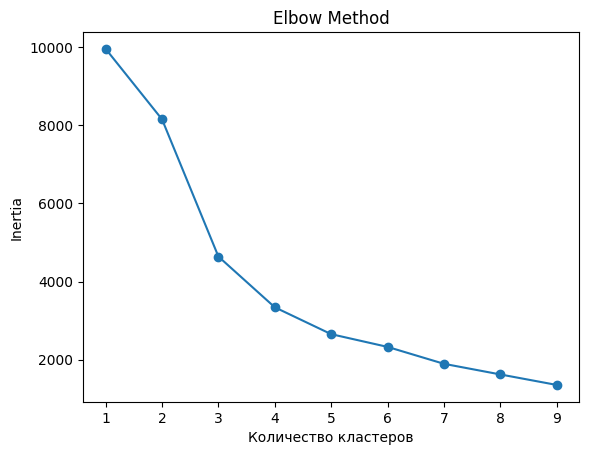

In [76]:
# Проведём кластеризацию:

# Разделим данные на тренировочные и тестовые, для того, чтобы проверить стабильность кластеров:
X_train, X_test = train_test_split(features, test_size=0.3, random_state=42)

# Маштабируем признаки:
scaler = StandardScaler()
cols_to_scale = ['Total Spent', 'Day_of_Week_num', 'Is_Weekend', 'place_Takeaway']
X_train[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])
X_test[cols_to_scale] = scaler.transform(X_test[cols_to_scale])

# Используем метод локтя, чтобы узнать на какое колличество кластеров делить данные:
inertias = []
for k in range(1, 10):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_train)
    inertias.append(kmeans.inertia_)


#print(inertias) # Каждое число — это сумма квадратов расстояний от точек до центроидов их кластеров при соответствующем k

plt.plot(range(1, 10), inertias, marker='o')
plt.xlabel('Количество кластеров')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()

In [77]:
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans.fit(X_train)

# Смотрим, насколько кластеры на тесте похожи на train
train_labels = kmeans.labels_
test_labels = kmeans.predict(X_test)

In [78]:
print(f"Коэффициент силуэта (train): {silhouette_score(X_train, train_labels):.3f}")
print(f"Коэффициент силуэта (test):  {silhouette_score(X_test, test_labels):.3f}")
print(f"\nРаспределение train:\n{pd.Series(train_labels).value_counts().sort_index()}")
print(f"\nРаспределение test:\n{pd.Series(test_labels).value_counts().sort_index()}")

Коэффициент силуэта (train): 0.341
Коэффициент силуэта (test):  0.336

Распределение train:
0     585
1     710
2    1194
Name: count, dtype: int64

Распределение test:
0    253
1    303
2    511
Name: count, dtype: int64


In [79]:
# Результаты: 0.341 и 0.336 — это умеренный результат. Кластеры разделены, но не идеально,
# есть перекрытия между кластерами.

In [80]:
# Silhouette - показал незначительное различие между результатами тренировочной и тестовой группами.
# Мы видем перекос данных в сторону класера-2, кластер_0 собрал самую маленькую группу.

In [81]:
# Добавим метки в датафрейм

features_scaled = pd.DataFrame(scaler.transform(features), columns=features.columns)
df_model_2['cluster'] = kmeans.predict(features_scaled)

# Посмотрим средние значения признаков и колличество покупателей в каждом кластере
print(df_model_2.groupby('cluster').agg({
  'Total Spent':'mean',
  'Day_of_Week_num':'mean',
  'Is_Weekend':'mean',
  'place_Takeaway':'mean',
  'cluster':'count'
}))

         Total Spent  Day_of_Week_num  Is_Weekend  place_Takeaway  cluster
cluster                                                                   
0          15.881862         2.972554         0.0        0.305489      838
1           9.073050         6.526160         1.0        0.503455     1013
2           5.533138         3.038123         0.0        0.597654     1705


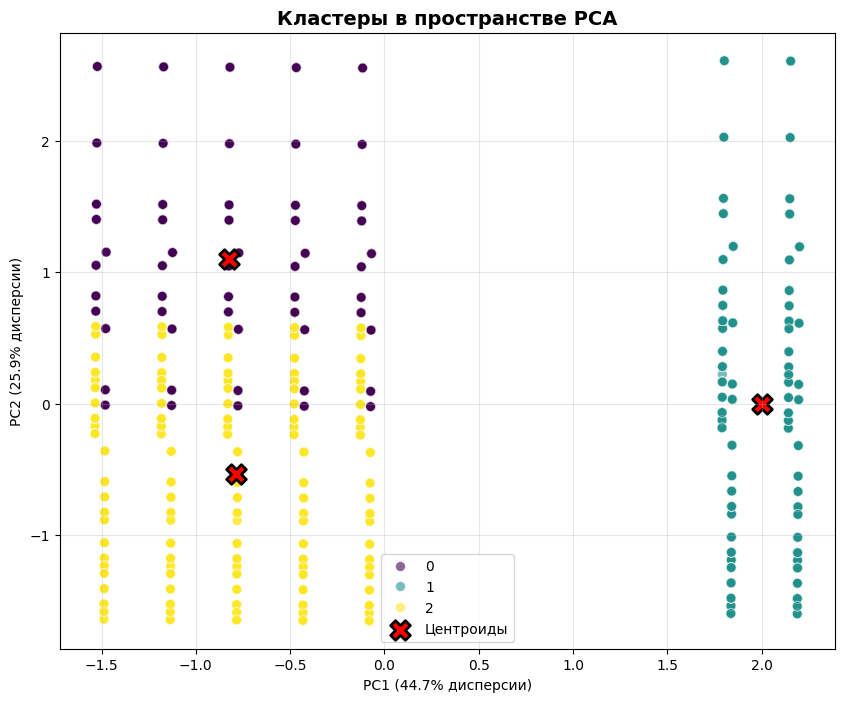

PC1 объясняет: 44.7%
PC2 объясняет: 25.9%
Вместе: 70.7% всей информации


In [82]:
# Масштабируем данные
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

# Применяем PCA (2 главные компоненты)
pca = PCA(n_components=2)
pca_result = pca.fit_transform(features_scaled)

# Создаем DataFrame с PCA результатами и метками из df_model_2
df_pca = pd.DataFrame({
    'PC1': pca_result[:, 0],
    'PC2': pca_result[:, 1],
    'cluster': df_model_2['cluster']  # ← используем метки из df_model_2
})

# Визуализация
plt.figure(figsize=(10, 8))
sns.scatterplot(data=df_pca, x='PC1', y='PC2', hue='cluster',
                palette='viridis', alpha=0.6, s=50)

# Добавляем центроиды (спроецированные)
centroids_pca = pca.transform(kmeans.cluster_centers_)
plt.scatter(centroids_pca[:, 0], centroids_pca[:, 1],
            c='red', s=200, marker='X',
            edgecolors='black', linewidths=2,
            label='Центроиды')

plt.title('Кластеры в пространстве PCA', fontsize=14, fontweight='bold')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} дисперсии)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} дисперсии)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Сколько информации сохранили
print(f"PC1 объясняет: {pca.explained_variance_ratio_[0]:.1%}")
print(f"PC2 объясняет: {pca.explained_variance_ratio_[1]:.1%}")
print(f"Вместе: {sum(pca.explained_variance_ratio_):.1%} всей информации")

In [83]:
# Is_Weekend - Главный разделяющий признак!